# v4 – Random forest and gradient boosting

The fifth model version. It keeps the workflow of [v3](v3_cv_tuning.ipynb) (seminar unit 4) and adds two ensemble models. This time all candidates are tuned, and the best of them is tested.

![Flow of v4_ensembles](images/v4_ensembles_flow.png)

**How to read it:** grey is the data, blue the training on the development data (the training cases), orange the prediction and the scores on the test cases. The vertical arrow is what training hands over: the pipeline of the selected model, refitted on all development data. Steps with a thick border and a tag are new in this version.

| | v3 | v4 |
|---|---|---|
| Candidates | baseline, Ridge, decision tree | baseline, Ridge, decision tree, **random forest, gradient boosting** |
| Tuning | only the decision tree | **every candidate**, each with its own grid, all with the same 5 folds |
| Tested model | the tuned tree (as in unit 4) | the candidate with the lowest CV error |
| Selection metric | MAE of log(τ) | the same |
| Classification | logistic regression for "t90 > 600 s" | left out |
| Data, target, inputs | v2: log(τ), log(wind speed) | the same |

The column meanings are in [results/README.md](../results/README.md).

## 1) Setup

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

VERSION = "v4_ensembles"
RANDOM_STATE = 42
LN10 = np.log(10)  # t90 = ln(10) * tau, see v1

DATA_PATH = Path("../results/dataset_550/dataset_550.csv")
RESULTS_DIR = Path("results")
print("Data file:", DATA_PATH, "| found:", DATA_PATH.exists())

Data file: ../results/dataset_550/dataset_550.csv | found: True


## 2) Load the data and split it

The same data and the same split as in every version (v0, sections 2 and 3). The training cases are the **development data**: models are fitted, compared and tuned only on them. The test cases stay untouched until section 5.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df["status"] == "ok"].set_index("case_id")

TARGET_COL = "t90_s"
# Only values that are fixed before a simulation starts (same choice as in unit 2)
FEATURE_COLS = [
    "layout",
    "window1_x_m",
    "window1_mode",
    "window1_angle_deg",
    "window1_hinge",
    "window2_x_m",
    "window2_mode",
    "window2_angle_deg",
    "window2_hinge",
    "wind_speed_ms",
]

print("Simulations:", len(df))
print("Missing input values:", int(df[FEATURE_COLS].isna().sum().sum()))

t90_reached = df[TARGET_COL].notna()
display(pd.crosstab(
    df["layout"],
    t90_reached.map({True: "t90 reached", False: "t90 > 600 s"}),
    margins=True,
    margins_name="total",
))

Simulations: 541
Missing input values: 0


t90_s,t90 > 600 s,t90 reached,total
layout,,,
adjacent_walls,22,228,250
opposite_walls,20,230,250
same_wall,34,7,41
total,76,465,541


In [3]:
strata = df["layout"] + " / " + np.where(t90_reached, "reached", "not reached")

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=strata,
)

print("Training simulations:", len(train_df))
print("Test simulations:    ", len(test_df))
display(pd.crosstab(test_df["layout"], test_df[TARGET_COL].notna().map({True: "t90 reached", False: "t90 > 600 s"})))

Training simulations: 432
Test simulations:     109


t90_s,t90 > 600 s,t90 reached
layout,,
adjacent_walls,5,46
opposite_walls,4,46
same_wall,7,1


In [4]:
TAU_COL = "tau_s"

X_dev, y_dev = train_df[FEATURE_COLS], np.log(train_df[TAU_COL])
X_test, y_test = test_df[FEATURE_COLS], np.log(test_df[TAU_COL])

print("Development data:", X_dev.shape, y_dev.shape)
print("Test data:       ", X_test.shape, y_test.shape)

Development data: (432, 10) (432,)
Test data:        (109, 10) (109,)


As in v1 and v2, the target is log(τ). All scores below are therefore scores of log(τ):

- an **MAE of log(τ)** of 0.22 means that τ is typically off by a factor of exp(0.22) ≈ 1.25, i.e. about 25 %;
- RMSE and R² are computed on log(τ) as well.

This MAE is the metric that selects the model. It was fixed before the tuning: a relative error counts the same for fast and for slow cases, and it uses every case.

## 3) Preprocessing and cross-validation

As in v3. The preprocessing is that of v2: log(wind speed), standardised numeric inputs, one-hot encoded categorical inputs. Our inputs have no missing values, so there is no imputer.

For the cross-validation two things are fixed:

- `KFold` splits the development data into 5 parts, the *folds*. The model is trained 5 times; each fold is the validation data once, while the other 4 folds are used for training.
- `regression_scoring` lists the scores computed in every run. Its keys (`mae`, …) name the entries in the result of `cross_validate`.

| Parameter | Meaning |
|---|---|
| `n_splits=5` | number of folds, and so the number of training runs |
| `shuffle=True` | mixes the rows before the folds are made |
| `random_state=42` | makes the mixing, and so the folds, reproducible |

The whole pipeline is fitted anew in every fold, so the log, the scaling and the one-hot categories are learned from that fold's training part only.

In [5]:
num_cols = X_dev.select_dtypes(include="number").columns.tolist()
cat_cols = [col for col in FEATURE_COLS if col not in num_cols]
WIND_COL = "wind_speed_ms"
other_num_cols = [col for col in num_cols if col != WIND_COL]


def build_preprocessor():
    log_wind = Pipeline(steps=[
        ("log", FunctionTransformer(np.log, feature_names_out=lambda transformer, names: ["log_wind_speed"])),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        transformers=[
            ("wind", log_wind, [WIND_COL]),
            ("num", StandardScaler(), other_num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

regression_scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

print("Numeric inputs:    ", len(num_cols))
print("Categorical inputs:", len(cat_cols))

Numeric inputs:     5
Categorical inputs: 5


## 4) Tune and compare the candidates

### 4.1 The candidates

| Model | Idea | Tuned settings |
|---|---|---|
| **Ridge** | linear model with a penalty on large coefficients (v0–v3) | `alpha`: strength of the penalty |
| **DecisionTree** | one tree of yes/no questions about the inputs (v0–v3) | `max_depth`, `min_samples_leaf`: the grid of unit 4 |
| **RandomForest** | many deep trees, each grown on a random resample of the training cases and with a random subset of the inputs at each split. The forest predicts their **average**, which smooths the steps of a single tree and reduces overfitting. | `max_depth`, `min_samples_leaf`, `max_features`: share of the inputs tried at each split |
| **GradientBoosting** | many small trees built **one after another**: each new tree corrects the remaining errors of the trees before it, scaled down by the `learning_rate`. A small learning rate needs more trees. | `n_estimators`: number of trees, `learning_rate`, `max_depth` of each tree |

Each candidate gets a `GridSearchCV` with the same folds as in v3. `scoring=regression_scoring` records MAE, RMSE and R² for every combination; `refit="mae"` makes the MAE of log(τ) the score that selects. The random forest has 300 trees; the random choices of both ensembles are fixed by `random_state`.

The gradient-boosting grid was first tried with `max_depth` up to 4 and at most 1000 trees. Its best combination lay at the edge of that grid, so the optimum could have been outside; the grid was extended to depth 6 and 2000 trees (section 4.3 shows that depth 4 is now inside). This was decided on the cross-validation only, before any test.

In [6]:
def pipeline_with(model):
    return Pipeline(steps=[
        ("preprocess", build_preprocessor()),
        ("model", model),
    ])


candidates = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    ),
    "DecisionTree": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5, 10]},
    ),
    "RandomForest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "model__max_depth": [8, 12, None],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": [0.33, 0.5, 1.0],
        },
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [300, 1000, 2000],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__max_depth": [2, 3, 4, 5, 6],
        },
    ),
}

searches = {}
for name, (model, grid) in candidates.items():
    start = time.time()
    searches[name] = GridSearchCV(
        estimator=pipeline_with(model),
        param_grid=grid,
        scoring=regression_scoring,
        refit="mae",
        cv=regression_cv,
        n_jobs=-1,
        return_train_score=True,
    ).fit(X_dev, y_dev)
    n_combinations = len(searches[name].cv_results_["params"])
    print(f"{name:17s} {n_combinations:3d} combinations x 5 folds in {time.time() - start:5.1f} s")

Ridge               5 combinations x 5 folds in   0.8 s


DecisionTree       16 combinations x 5 folds in   0.3 s


RandomForest       27 combinations x 5 folds in   6.5 s


GradientBoosting   45 combinations x 5 folds in  37.9 s


### 4.2 Comparison

For each candidate, the row shows its best combination. The baseline is cross-validated with the same folds, as in v3.

In [7]:
baseline_cv = cross_validate(
    pipeline_with(DummyRegressor(strategy="median")),
    X_dev,
    y_dev,
    cv=regression_cv,
    scoring=regression_scoring,
    return_train_score=True,
)

rows = [{
    "model": "Baseline (median)",
    "best settings": "–",
    "training MAE": -baseline_cv["train_mae"].mean(),
    "CV MAE": -baseline_cv["test_mae"].mean(),
    "CV MAE std": baseline_cv["test_mae"].std(),
    "CV RMSE": -baseline_cv["test_rmse"].mean(),
    "CV R²": baseline_cv["test_r2"].mean(),
}]
for name, search in searches.items():
    i, r = search.best_index_, search.cv_results_
    rows.append({
        "model": name,
        "best settings": ", ".join(f"{k.removeprefix('model__')}={v}" for k, v in search.best_params_.items()),
        "training MAE": -r["mean_train_mae"][i],
        "CV MAE": -r["mean_test_mae"][i],
        "CV MAE std": r["std_test_mae"][i],
        "CV RMSE": -r["mean_test_rmse"][i],
        "CV R²": r["mean_test_r2"][i],
    })

comparison = pd.DataFrame(rows).set_index("model").sort_values("CV MAE")
comparison["typical τ error"] = (np.exp(comparison["CV MAE"]) - 1).map("{:.0%}".format)
display(comparison.round(3))

,best settings,training MAE,CV MAE,CV MAE std,CV RMSE,CV R²,typical τ error
model,,,,,,,
GradientBoosting,"learning_rate=0.02, max_depth=4, n_estimators=...",0.005,0.147,0.019,0.198,0.947,16%
RandomForest,"max_depth=None, max_features=1.0, min_samples_...",0.067,0.182,0.008,0.246,0.919,20%
DecisionTree,"max_depth=8, min_samples_leaf=1",0.065,0.219,0.022,0.304,0.875,24%
Ridge,alpha=0.1,0.211,0.221,0.018,0.261,0.908,25%
Baseline (median),–,0.701,0.705,0.027,0.870,-0.014,102%


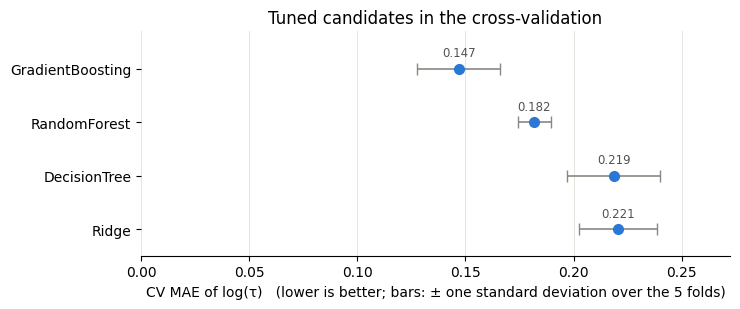

In [8]:
tuned = comparison.drop(index="Baseline (median)").sort_values("CV MAE", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.errorbar(
    tuned["CV MAE"], tuned.index, xerr=tuned["CV MAE std"],
    fmt="o", color="#2a78d6", ecolor="#898781", elinewidth=1.2, capsize=4, markersize=7,
)
for value, name in zip(tuned["CV MAE"], tuned.index):
    ax.annotate(f"{value:.3f}", (value, name), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=8.5, color="#52514e")
ax.set_xlim(0, tuned["CV MAE"].max() + tuned["CV MAE std"].max() + 0.03)
ax.set_ylim(-0.5, len(tuned) - 0.3)  # room for the value labels above the top point
ax.set_xlabel("CV MAE of log(τ)   (lower is better; bars: ± one standard deviation over the 5 folds)")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.set_title("Tuned candidates in the cross-validation")
fig.tight_layout()
plt.show()

### 4.3 Is the best setting inside the grid?

If the best value of a setting is the largest or the smallest value tried, the true optimum may lie outside the grid. The table shows, for each value of a setting, the best CV MAE over all other settings.

In [9]:
for name in ["RandomForest", "GradientBoosting"]:
    results = pd.DataFrame(searches[name].cv_results_)
    results["CV MAE"] = -results["mean_test_mae"]
    for parameter, grid_values in candidates[name][1].items():
        values = results[f"param_{parameter}"].astype(str)  # as text, so that None is kept
        best_per_value = {str(v): round(results.loc[values == str(v), "CV MAE"].min(), 4) for v in grid_values}
        print(f"{name:17s} {parameter.removeprefix('model__'):17s}", best_per_value)

RandomForest      max_depth         {'8': 0.1839, '12': 0.1823, 'None': 0.1819}
RandomForest      min_samples_leaf  {'1': 0.1819, '2': 0.1889, '4': 0.208}
RandomForest      max_features      {'0.33': 0.21, '0.5': 0.1853, '1.0': 0.1819}
GradientBoosting  n_estimators      {'300': 0.1488, '1000': 0.1473, '2000': 0.1469}
GradientBoosting  learning_rate     {'0.02': 0.1469, '0.05': 0.1472, '0.1': 0.1499}
GradientBoosting  max_depth         {'2': 0.1622, '3': 0.1528, '4': 0.1469, '5': 0.1584, '6': 0.1624}


For gradient boosting, depth 4 lies inside the grid (depths 5 and 6 are worse), and more than 1000 trees hardly change the result. For the random forest, the best values are the most flexible ones (unlimited depth, leaf size 1, all inputs at each split); the grid cannot go further in that direction.

### 4.4 Selection

The rule, as in v3 and unit 4: **the candidate with the lowest mean CV MAE of log(τ)** is selected. Its `best_estimator_` has already been refitted on all 432 development cases.

In [10]:
selected_name = comparison.drop(index="Baseline (median)")["CV MAE"].idxmin()
selected = searches[selected_name].best_estimator_

print("Selected:", selected_name)
print("Settings:", comparison.loc[selected_name, "best settings"])
print(f"CV MAE of log(τ): {comparison.loc[selected_name, 'CV MAE']:.3f} ± {comparison.loc[selected_name, 'CV MAE std']:.3f}")

Selected: GradientBoosting
Settings: learning_rate=0.02, max_depth=4, n_estimators=2000
CV MAE of log(τ): 0.147 ± 0.019


## 5) Final evaluation on the test cases

The selected pipeline is now applied to the test cases, for the first and only time in this version. The scores of unit 4 are on log(τ); the plots are those of v3.

In [11]:
y_pred = selected.predict(X_test)

test_results = pd.Series({
    "MAE of log(τ)": mean_absolute_error(y_test, y_pred),
    "RMSE of log(τ)": root_mean_squared_error(y_test, y_pred),
    "R² of log(τ)": r2_score(y_test, y_pred),
})

display(test_results.round(3).to_frame(f"test value, {selected_name}"))

,"test value, GradientBoosting"
MAE of log(τ),0.171
RMSE of log(τ),0.245
R² of log(τ),0.923


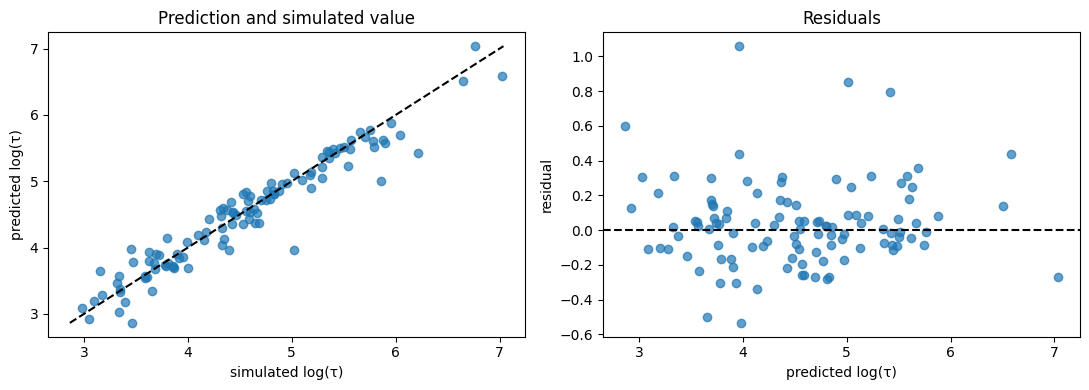

In [12]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(y_test, y_pred, alpha=0.7)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set_xlabel("simulated log(τ)")
axes[0].set_ylabel("predicted log(τ)")
axes[0].set_title("Prediction and simulated value")

axes[1].scatter(y_pred, residuals, alpha=0.7)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set_xlabel("predicted log(τ)")
axes[1].set_ylabel("residual")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

**For the comparison with the earlier versions:** t90 = ln(10) · τ on the same 93 test cases with a t90 value, and how many of the 16 test cases without t90 get a predicted t90 above 600 s. Both are only reported; nothing is selected with them.

In [13]:
has_t90 = test_df[TARGET_COL].notna()
y_test_t90 = test_df.loc[has_t90, TARGET_COL]
t90_pred = pd.Series(LN10 * np.exp(y_pred), index=X_test.index)

t90_results = pd.Series({
    "MAE [s]": mean_absolute_error(y_test_t90, t90_pred[has_t90]),
    "RMSE [s]": root_mean_squared_error(y_test_t90, t90_pred[has_t90]),
    "R²": r2_score(y_test_t90, t90_pred[has_t90]),
})
display(t90_results.round(3).to_frame(f"{selected_name}, t90 on the 93"))

slow = ~has_t90
print(f"Test cases without t90 predicted as t90 > 600 s: {(t90_pred[slow] > 600).sum()} of {slow.sum()}")
print(f"Test cases with t90 predicted as t90 > 600 s (wrong): {(t90_pred[has_t90] > 600).sum()} of {has_t90.sum()}")

earlier = pd.concat([
    pd.read_csv(RESULTS_DIR / f"{v}.csv") for v in ["v0_base", "v1_tau", "v2_log_wind", "v3_cv_tuning"]
])
display(earlier[earlier["model"] != "Mean value (reference)"][["version", "model", "MAE [s]", "R²"]].round(3))

,"GradientBoosting, t90 on the 93"
MAE [s],31.188
RMSE [s],46.965
R²,0.890


Test cases without t90 predicted as t90 > 600 s: 12 of 16
Test cases with t90 predicted as t90 > 600 s (wrong): 0 of 93


,version,model,MAE [s],R²
1,v0_base,LinearRegression,53.050,0.753
2,v0_base,Ridge,53.450,0.734
3,v0_base,DecisionTree,42.081,0.806
1,v1_tau,LinearRegression,50.206,0.713
2,v1_tau,Ridge,50.135,0.704
3,v1_tau,DecisionTree,57.922,0.638
1,v2_log_wind,LinearRegression,47.322,0.745
2,v2_log_wind,Ridge,47.252,0.736
3,v2_log_wind,DecisionTree,57.922,0.638
0,v3_cv_tuning,"DecisionTree (depth 8, leaf 1)",43.805,0.795


## 6) What the selected model learned

`feature_importances_` gives the share of the error reduction that each input achieves in the trees. The one-hot columns of a categorical input are added up, so there is one value per input.

As in v2, tilt, a 6° angle and `hinge = none` always occur together, so the importance of tilting is shared between these inputs in some way; read their values together.

In [14]:
fitted_model = selected.named_steps["model"]
feature_names = selected.named_steps["preprocess"].get_feature_names_out()


def input_of(feature):
    if feature == "log_wind_speed":
        return "wind_speed_ms (as log)"
    return next(col for col in FEATURE_COLS if feature == col or feature.startswith(col + "_"))


if hasattr(fitted_model, "feature_importances_"):
    importances = pd.Series(fitted_model.feature_importances_, index=feature_names)
    per_input = importances.groupby(importances.index.map(input_of)).sum().sort_values(ascending=False)
    display(per_input.round(3).to_frame(f"{selected_name} importance"))
else:
    print(selected_name, "has no feature importances")

,GradientBoosting importance
wind_speed_ms (as log),0.233
window1_angle_deg,0.187
window2_angle_deg,0.175
layout,0.135
window2_mode,0.097
window1_mode,0.067
window2_hinge,0.044
window1_hinge,0.037
window1_x_m,0.022
window2_x_m,0.004


## 7) Save the results

As in the earlier versions: `results/v4_ensembles.csv` holds the t90 scores of the selected pipeline on the 93 test cases, `results/v4_ensembles_test_predictions.csv` its predicted t90 and τ for all 109 test cases. `results/v4_ensembles_cv.csv` adds the cross-validation comparison of section 4.2.

In [15]:
model_name = f"{selected_name} ({comparison.loc[selected_name, 'best settings']})"
summary = pd.DataFrame([{
    "version": VERSION,
    "model": model_name,
    **t90_results.to_dict(),
    "target": "log(tau_s)",
    "n_train": len(X_dev),
    "n_test": len(y_test_t90),
}])
summary.to_csv(RESULTS_DIR / f"{VERSION}.csv", index=False, float_format="%.3f")

comparison.drop(columns="typical τ error").to_csv(RESULTS_DIR / f"{VERSION}_cv.csv", float_format="%.4f")

test_predictions = pd.DataFrame({
    "t90_s simulated": test_df[TARGET_COL],
    "tau_s simulated": test_df[TAU_COL],
    f"t90 {selected_name}": t90_pred,
    f"tau {selected_name}": np.exp(y_pred),
}, index=X_test.index)
test_predictions.to_csv(RESULTS_DIR / f"{VERSION}_test_predictions.csv", index_label="case_id", float_format="%.1f")
display(summary.round(3))

,version,model,MAE [s],RMSE [s],R²,target,n_train,n_test
0,v4_ensembles,"GradientBoosting (learning_rate=0.02, max_dept...",31.188,46.965,0.89,log(tau_s),432,93


## 8) Summary and findings

**Cross-validation** (432 development cases, MAE of log(τ)):

| Model | CV MAE | typical τ error |
|---|---|---|
| GradientBoosting (depth 4, 2000 trees, learning rate 0.02) | 0.147 ± 0.019 | 16 % |
| RandomForest (300 deep trees, all inputs per split) | 0.182 ± 0.008 | 20 % |
| DecisionTree (depth 8, leaf 1, as in v3) | 0.219 ± 0.022 | 24 % |
| Ridge (alpha 0.1) | 0.221 ± 0.018 | 25 % |

- Both ensembles beat the single models clearly, by more than the variation between the folds. Gradient boosting is best and is selected.
- Gradient boosting fits its training data almost perfectly (training MAE 0.005), so the gap to the CV error is large. Its CV error is still the lowest; the cross-validation, not the training error, decides.
- The random forest varies least between the folds (± 0.008).
- The optimum of gradient boosting lies inside the grid (section 4.3). Above 1000 trees, the result hardly changes.

**Test** (once, gradient boosting): MAE of log(τ) 0.171, a little worse than in the cross-validation (0.147), as is normal for a selected model; R² of log(τ) 0.92. In t90 on the 93 test cases: **MAE 31 s, RMSE 47 s, R² 0.89**, the best of all versions so far (v0's tree: 42 s, 0.81; v3: 44 s, 0.80). It also recognises 12 of the 16 test cases that take longer than 600 s, with no false alarm among the 93 others.

**What it learned** (section 6): the wind speed matters most, then the two opening angles and the layout, then the window modes. The window positions along the wall hardly matter (2 % and 0.4 %).

**Weak point: same-wall windows.** The three largest test errors are all same-wall cases, where the model predicts τ 2 to 3 times too short, i.e. too fast an air exchange. There are only 33 same-wall cases among the 432 development cases, they come from the other simulation method (B), and the wind acts on them differently (v0, section 9).

**Options for the next version (v5):**

1. Save the selected pipeline with `joblib`, as in the second notebook of unit 4, so that it can be used without retraining.
2. More same-wall training data: a new simulation run with only same-wall cases (method B, about 1.5 h each on the simulation PC).
3. Look at the errors per layout in the cross-validation, to see whether a separate model for same-wall cases would help.
4. Final check on `test-v1` (30 new simulations, 10 per layout) once the tracer settings are fixed (PLAN.md §9).